# 2 · Housing


Presenter: Angelica Wu

Converted from `housing_fertility_analysis.py` and `Final_Report.md`. The original `BirthRate.csv`, `HDB_Resale_Price.csv` and `Private_Housing_Annual.csv` inputs are now read from `Housing_Data.csv`; the cleaned tables and charts are identical.

Housing costs may influence family formation by affecting resources available for raising children. Higher housing expenditure could encourage couples to postpone parenthood, while existing homeowners may benefit from rising property values. This analysis examines housing price trends and fertility from 2000 to 2025, with a separate 2020 Census snapshot of households with children.

Data: `Housing_Data.csv` (this member's columns of the group dataset).

In [1]:
from pathlib import Path
import os
import pandas as pd

# Locate this member's folder (the folder that contains Housing_Data.csv).
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'Housing_Data.csv').is_file())
COMBINED = pd.read_csv(ROOT / 'Housing_Data.csv', float_precision='round_trip')

# Each section reads its own columns from the one combined dataset, under the column names its code expects.
SECTIONS = {
    'healthcare': dict(years=(2010, 2025), integer=['year', 'resident_live_births_number'], columns={
        'Year': 'year', 'TFR': 'tfr_per_female',
        'resident_live_births_number': 'resident_live_births_number',
        'cpi_health_2024_100': 'cpi_health_2024_100',
        'cpi_medicines_health_products_2024_100': 'cpi_medicines_health_products_2024_100',
        'cpi_outpatient_care_2024_100': 'cpi_outpatient_care_2024_100',
        'cpi_inpatient_care_2024_100': 'cpi_inpatient_care_2024_100',
        'cpi_other_health_services_2024_100': 'cpi_other_health_services_2024_100',
        'cpi_health_insurance_2024_100': 'cpi_health_insurance_2024_100',
        'cpi_polyclinic_fees_2024_100': 'cpi_polyclinic_fees_2024_100',
        'cpi_gp_fees_2024_100': 'cpi_gp_fees_2024_100',
        'cpi_specialist_outpatient_fees_2024_100': 'cpi_specialist_outpatient_fees_2024_100',
        'gov_health_development_sgd_million': 'gov_health_development_sgd_million',
        'gov_health_operating_sgd_million': 'gov_health_operating_sgd_million',
        'doctors_per_10000_total_population': 'doctors_per_10000_total_population',
        'nurses_per_10000_total_population': 'nurses_per_10000_total_population',
        'acute_hospital_beds_total_number': 'acute_hospital_beds_total_number',
        'acute_hospital_beds_public_number': 'acute_hospital_beds_public_number',
        'acute_hospital_beds_nonprofit_number': 'acute_hospital_beds_nonprofit_number',
        'acute_hospital_beds_private_number': 'acute_hospital_beds_private_number',
        'acute_hospitals_public_number': 'acute_hospitals_public_number',
        'acute_hospitals_private_number': 'acute_hospitals_private_number',
        'public_polyclinics_number': 'public_polyclinics_number',
        'young_children_health_inflation_2019base_pct': 'young_children_health_inflation_2019base_pct',
        'general_households_health_inflation_2019base_pct': 'general_households_health_inflation_2019base_pct',
        'Gov_Health_per_Capita': 'gov_health_per_capita_sgd',
        'Gov_Health_Total': 'gov_health_expenditure_sgd_million',
        'Gov_Health_%_GDP': 'gov_health_expenditure_gdp_pct',
        'HES_Health_Monthly': 'hes_all_households_health_monthly_sgd',
        'HES_Health_Share_%': 'hes_all_households_health_share_pct'},
        order=['year',
               'tfr_per_female',
               'resident_live_births_number',
               'cpi_health_2024_100',
               'cpi_medicines_health_products_2024_100',
               'cpi_outpatient_care_2024_100',
               'cpi_inpatient_care_2024_100',
               'cpi_other_health_services_2024_100',
               'cpi_health_insurance_2024_100',
               'cpi_polyclinic_fees_2024_100',
               'cpi_gp_fees_2024_100',
               'cpi_specialist_outpatient_fees_2024_100',
               'gov_health_per_capita_sgd',
               'gov_health_expenditure_sgd_million',
               'gov_health_expenditure_gdp_pct',
               'gov_health_development_sgd_million',
               'gov_health_operating_sgd_million',
               'doctors_per_10000_total_population',
               'nurses_per_10000_total_population',
               'hes_all_households_health_monthly_sgd',
               'hes_all_households_health_share_pct',
               'acute_hospital_beds_total_number',
               'acute_hospital_beds_public_number',
               'acute_hospital_beds_nonprofit_number',
               'acute_hospital_beds_private_number',
               'acute_hospitals_public_number',
               'acute_hospitals_private_number',
               'public_polyclinics_number',
               'young_children_health_inflation_2019base_pct',
               'general_households_health_inflation_2019base_pct']),
    'housing_hdb_quarterly': dict(years=(2000, 2025), integer=['Year'], columns={
        'Year': 'Year', 'HDB_Resale_Index_Q4': '4', 'HDB_Resale_Index_Q3': '3',
        'HDB_Resale_Index_Q2': '2', 'HDB_Resale_Index_Q1': '1'}),
    'housing_fertility': dict(years=(2000, 2025), integer=['Year'], columns={
        'Year': 'Year', 'TFR': 'Total_Fertility_Rate',
        **{f'ASFR_{a}_{a + 4}': f'{a} - {a + 4} Years' for a in range(15, 50, 5)}}),
    'housing_private': dict(years=(2000, 2025), integer=['Year'], columns={
        'Year': 'Year', 'Private_Landed_Index_URA': 'Private_Landed_Index',
        'Private_Non_Landed_Index_URA': 'Private_Non_Landed_Index'}),
    'marriage': dict(years=(2000, 2025), integer=['Year'], columns={c: c for c in [
        'Year', 'TFR', 'F_Marriage_Rate_20_24', 'F_Marriage_Rate_25_29', 'F_Marriage_Rate_30_34',
        'F_Marriage_Rate_35_39', 'F_Marriage_Rate_40_44', 'Median_Age_First_Birth', 'Brides_25_29', 'Brides_30_34']}),
    'income': dict(years=(2010, 2025), integer=['Year'], columns={c: c for c in ['Year', 'TFR', 'PM_Avg', 'PM_Median', 'CPI_All_Items_2024_100', 'CPI_All_Items_2010_100', 'PM_Avg_Real_2010', 'PM_Median_Real_2010', 'Real_Growth_%', 'Real_Growth_D1', 'Real_Growth_D2', 'Real_Growth_D3', 'Real_Growth_D4', 'Real_Growth_D5', 'Real_Growth_D6', 'Real_Growth_D7', 'Real_Growth_D8', 'Real_Growth_D9', 'Gini_Before_Transfers', 'Gini_After_Transfers', 'Real_Growth_D1_M810361', 'Real_Growth_D10_M810361']}),
    'education': dict(years=(2000, 2025), integer=['Year'],
                      columns={c: c for c in ['Year', 'TFR', 'ASFR_15_19', 'ASFR_20_24', 'ASFR_25_29', 'ASFR_30_34', 'ASFR_35_39', 'ASFR_40_44', 'Gini_Before_Transfers', 'Gini_After_Transfers', 'Income_Decile_1', 'Income_Decile_2', 'Income_Decile_3', 'Income_Decile_4', 'Income_Decile_5', 'Income_Decile_6', 'Income_Decile_7', 'Income_Decile_8', 'Income_Decile_9', 'F_Marriage_Rate_20_24', 'F_Marriage_Rate_25_29', 'F_Marriage_Rate_30_34', 'F_Marriage_Rate_35_39', 'F_Marriage_Rate_40_44', 'Median_Age_First_Birth', 'Brides_25_29', 'Brides_30_34', 'PM_Avg', 'PM_Median', 'Real_Growth_%', 'CPI_All_Items_2024_100', 'CPI_All_Items_2010_100', 'PM_Avg_Real_2010', 'PM_Median_Real_2010', 'Real_Growth_D1', 'Real_Growth_D2', 'Real_Growth_D3', 'Real_Growth_D4', 'Real_Growth_D5', 'Real_Growth_D6', 'Real_Growth_D7', 'Real_Growth_D8', 'Real_Growth_D9', 'Real_Growth_D1_M810361', 'Real_Growth_D10_M810361', 'HH_Size_Employed', 'HDB_Resale_Price_Index', 'Private_Landed_Index', 'Private_Non_Landed_Index', 'HDB_YoY_%', 'Landed_YoY_%', 'NonLanded_YoY_%', 'Edu_CPI', 'Edu_CPI_General', 'Edu_CPI_Tuition', 'Edu_CPI_Textbooks', 'Edu_Public_Total', 'Edu_Primary_per_Student', 'Edu_Secondary_per_Student', 'Edu_Op_Primary', 'Edu_Op_Secondary_JC', 'Edu_Op_Tertiary', 'Edu_Op_Other', 'Edu_Op_ITE', 'Edu_Development', 'Univ_Women_25_34_%', 'Univ_Women_35_44_%', 'Childcare_Places', 'Preschool_Age6_%', 'Pupils_per_Teacher', 'Health_CPI', 'Health_CPI_Medicines', 'Health_CPI_Outpatient', 'Health_CPI_Inpatient', 'Health_CPI_Other', 'Health_CPI_Insurance', 'HES_Health_Monthly', 'HES_Health_Share_%', 'Gov_Health_Total', 'Gov_Health_per_Capita', 'Gov_Health_%_GDP']}),
}


def load_section(name):
    spec = SECTIONS[name]
    y0, y1 = spec['years']
    frame = COMBINED.loc[COMBINED.Year.between(y0, y1), list(spec['columns'])]
    frame = frame.rename(columns=spec['columns']).reset_index(drop=True)
    if spec.get('order'):
        frame = frame[spec['order']]
    for column in spec['integer']:
        frame[column] = frame[column].astype('int64')
    return frame


print(f'Housing_Data.csv: {COMBINED.shape[0]} years × {COMBINED.shape[1]} columns')

Housing_Data.csv: 26 years × 15 columns


### Data notes

Inputs: original uploaded BirthRate.csv and HDB_Resale_Price.csv; annual private housing indices from the previously verified URA annual comparison. Private_Housing_Annual.csv contains annual averages, not individual transactions.

Sources:
- Private housing: https://data.gov.sg/datasets/d_da00b36ca8c831322fa0bb2a3378a476/view
- Household comparison: https://data.gov.sg/datasets/d_7363ba6451d9a8e25d8c081b553b6c6c/view (Census 2020, CT/17486, revised June 2026)
- Fertility: uploaded SingStat BirthRate.csv, total fertility and age-specific fertility series.
- HDB: uploaded SingStat HDB_Resale_Price.csv, quarterly HDB Resale Price Index.

Household counts are a documented 2020 snapshot entered in the script: HDB with/without children 526014/181701; condos 120714/36881; landed 43865/10970. Private combines condos and landed. Percentages use married-couple households only. These are not annual births or fertility rates. Children may be adults, and children living elsewhere are not counted in that household category.

Outputs: five PNG charts, annual cleaned HDB data, merged 2000–2025 data, household data, and age-specific correlations.

HDB annual averages require four distinct quarters. Total fertility is read directly, not calculated from rounded age-specific rates. All housing indices are rebased to 2000 = 100. Pearson correlations use annual levels and may reflect shared time trends. They are not causal estimates. No income adjustment or age adjustment is applied to household comparisons.

In [2]:
# Housing outputs (charts and cleaned tables) are saved under sections/housing/outputs.
(ROOT / 'sections' / 'housing').mkdir(parents=True, exist_ok=True)
os.chdir(ROOT / 'sections' / 'housing')

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
from IPython.display import Image, display

matplotlib.rcdefaults()   # start from matplotlib defaults, as the original stand-alone script did
BASE = Path.cwd()
OUT = BASE / 'outputs'
OUT.mkdir(exist_ok=True)
START, END = 2000, 2025
AGES = [f'{a} - {a+4} Years' for a in range(15, 50, 5)]
LABELS = [f'{a}–{a+4}' for a in range(15, 50, 5)]
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.facecolor': 'white'})


def save(fig, filename, note):
    fig.text(.08, .025, note, fontsize=9, color='#58677c')
    fig.savefig(OUT / filename, dpi=220, bbox_inches='tight')
    plt.close(fig)

In [3]:
# 1. Convert HDB quarterly data to annual averages; require four distinct quarters.
# Combined notebook: quarterly HDB index read from Fertility_Combined_Data.csv (4Q to 1Q, as in the SingStat file).
hdb_quarters = load_section('housing_hdb_quarterly')
q = hdb_quarters.melt(id_vars='Year', var_name='Quarter', value_name='Index')
q = q.dropna().astype({'Year': int, 'Quarter': int})
if q.duplicated(['Year', 'Quarter']).any():
    raise ValueError('Duplicate HDB quarterly observations.')
complete = q.groupby('Year')['Quarter'].nunique()
hdb = q[q.Year.isin(complete[complete.eq(4)].index)].groupby('Year')['Index'].mean()
hdb = hdb.rename('HDB_Resale_Price_Index').reset_index()

# 2. Read total fertility and age-specific fertility as distinct measures.
# Combined notebook: fertility and URA private indices read from Fertility_Combined_Data.csv.
fertility = load_section('housing_fertility')
private = load_section('housing_private')
df = hdb.merge(fertility, on='Year', validate='one_to_one').merge(
    private, on='Year', validate='one_to_one')
df = df[df.Year.between(START, END)].sort_values('Year').reset_index(drop=True)
if df.Year.tolist() != list(range(START, END+1)) or df.isna().any().any():
    raise ValueError('Expected complete annual data for 2000–2025.')
price_cols = ['HDB_Resale_Price_Index', 'Private_Landed_Index', 'Private_Non_Landed_Index']
for col in price_cols:
    df[col + '_2000_100'] = df[col] / df.loc[0, col] * 100
hdb[hdb.Year.between(START, END)].to_csv(OUT/'HDB_Annual_Cleaned.csv', index=False)
df.to_csv(OUT/'Housing_Fertility_Merged_2000_2025.csv', index=False)

## Figure 1: Housing Price Indices and Total Fertility Rate in Singapore, 2000–2025

Quarterly housing indices are averaged by year, then rebased to 2000 = 100. Housing indices use the left axis; total fertility uses the right axis.

HDB resale prices increased by 159.2%, compared with 145.5% for private landed homes and 112.1% for private condos and apartments. Total fertility declined from 1.60 to 0.87 children per woman, approximately 45.6%. These opposing long-term trends support investigating housing costs as a potential factor associated with family formation, but do not establish causation. Price indices measure price growth rather than dollar prices or affordability. Income, subsidies, financing costs and family preferences also matter. Line intersections have no numerical meaning because the axes use different units.

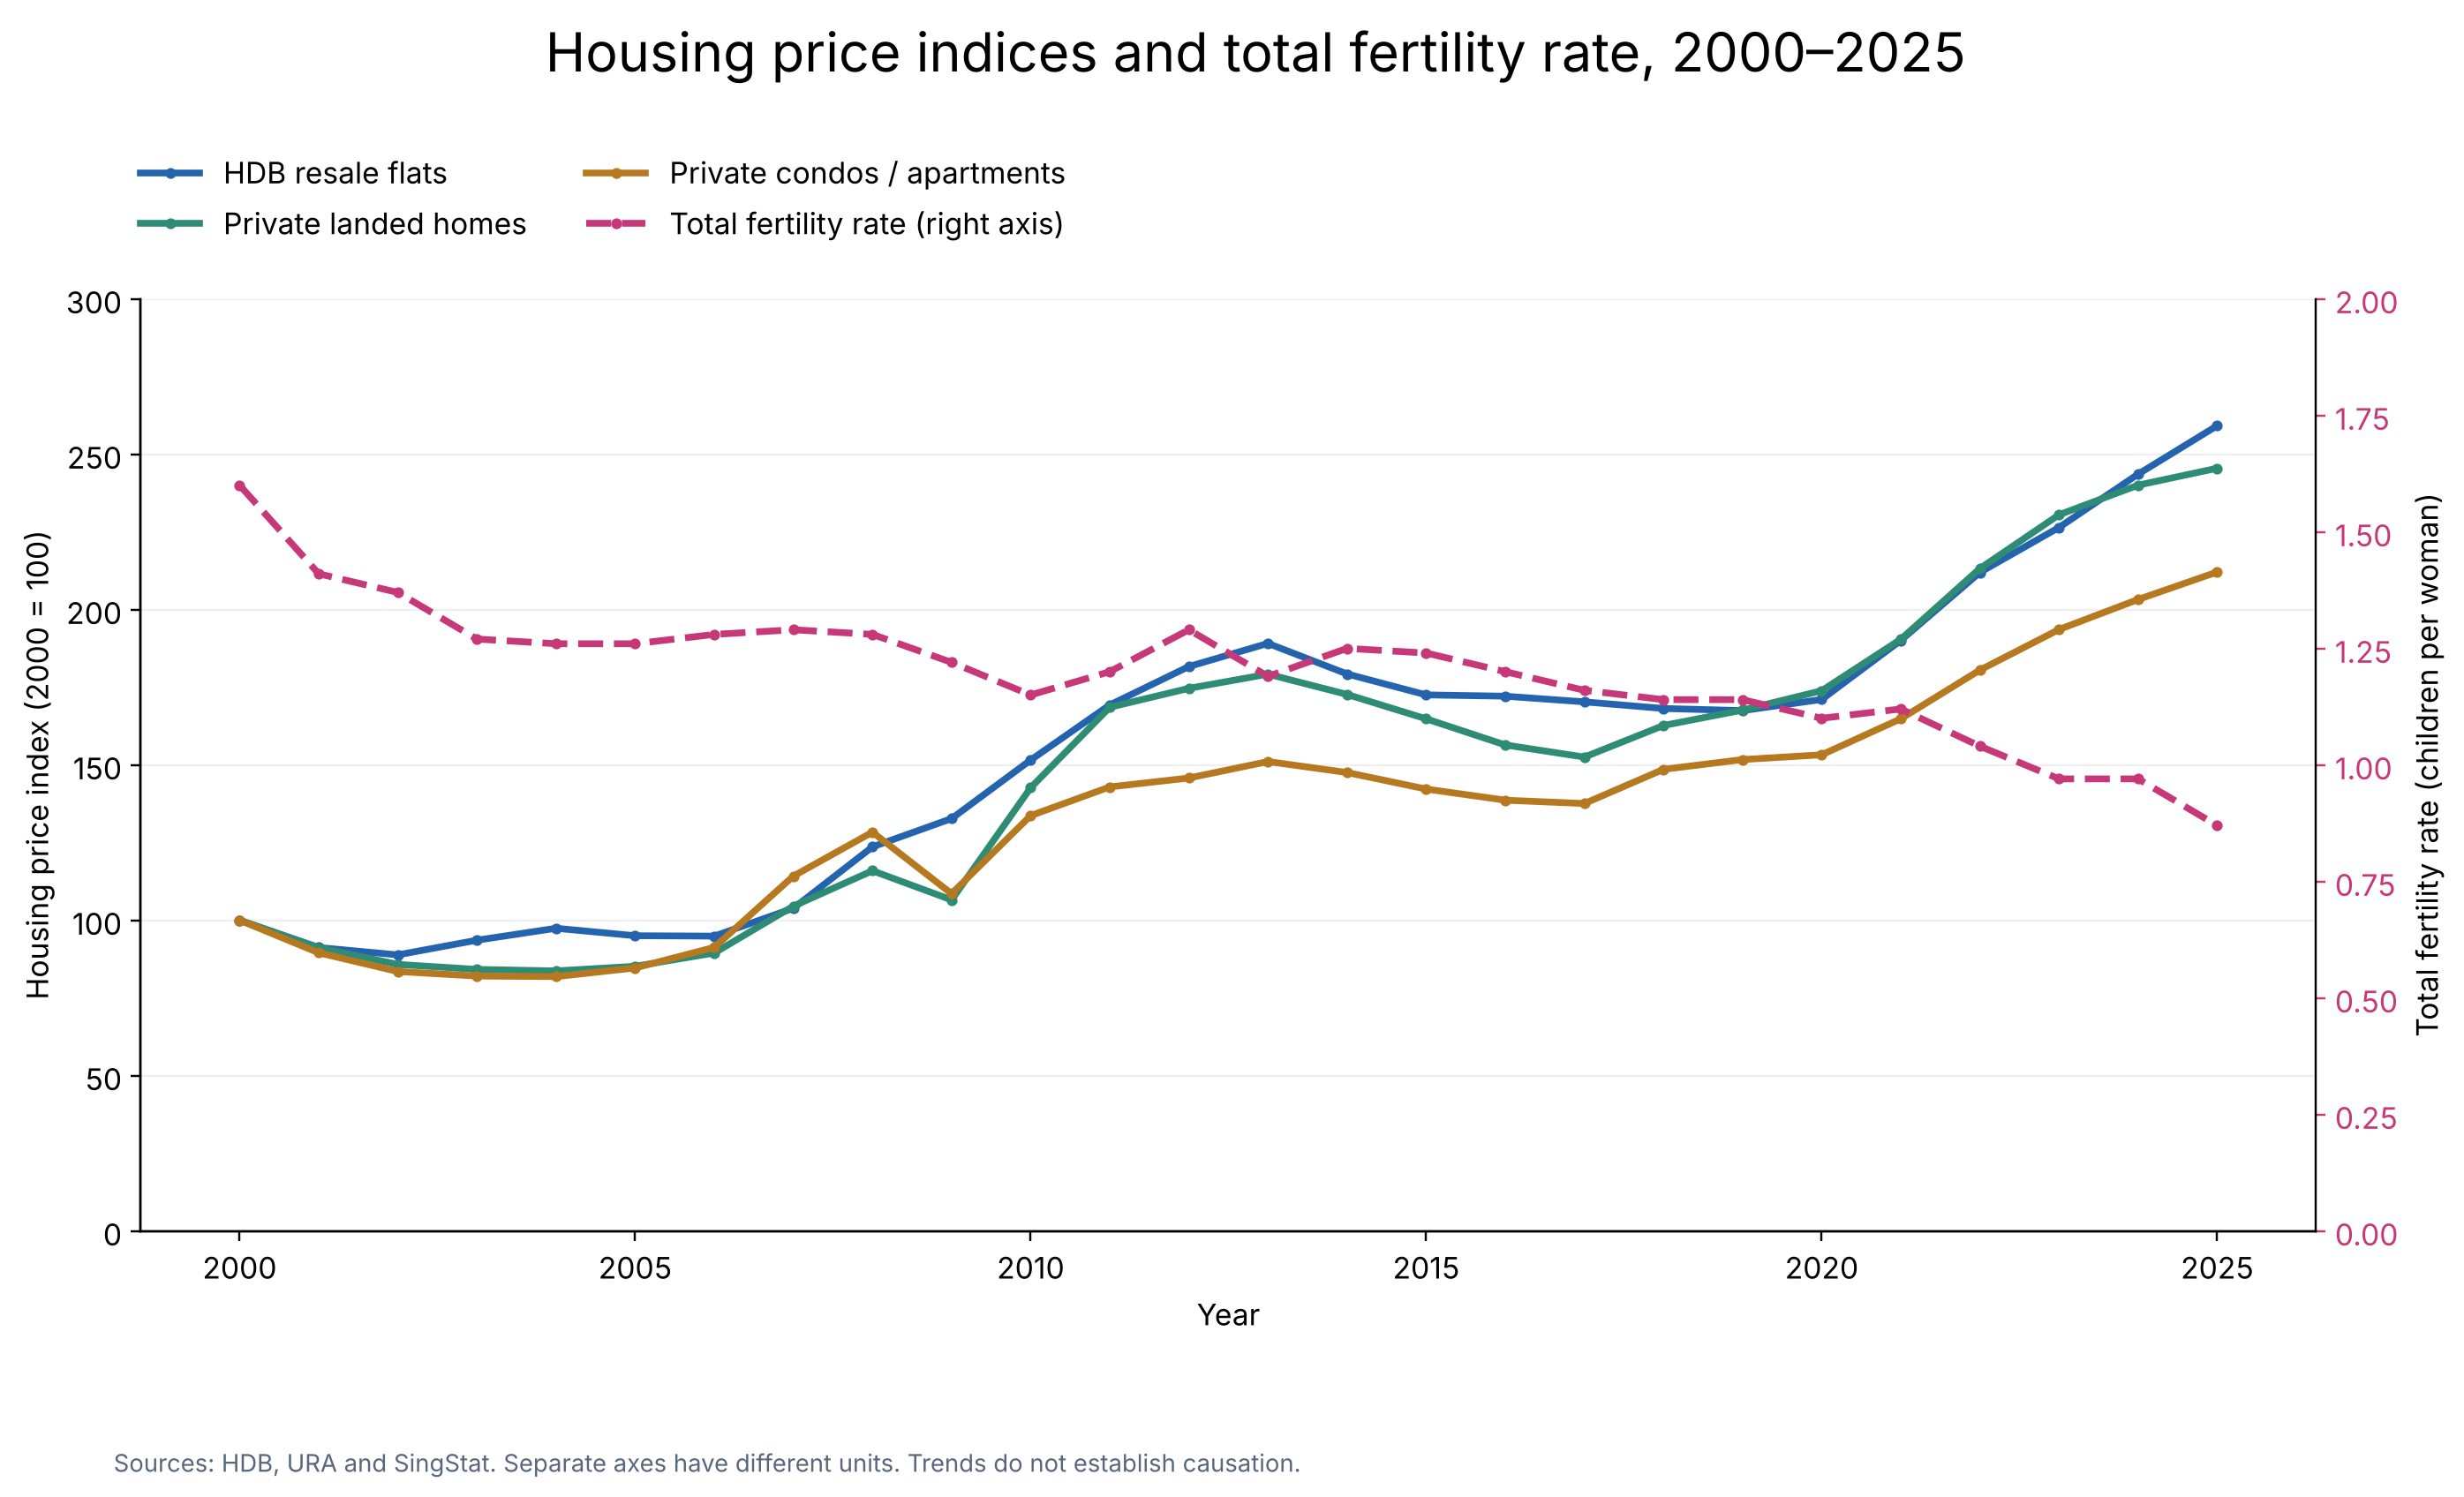

In [4]:
# 3. Combined housing-price and fertility chart.
fig, ax = plt.subplots(figsize=(14, 8))
fig.subplots_adjust(left=.09, right=.89, top=.78, bottom=.18)
fig.suptitle('Housing price indices and total fertility rate, 2000–2025', fontsize=20, y=.96)
lines = []
for col, label, color in zip(price_cols,
        ['HDB resale flats', 'Private landed homes', 'Private condos / apartments'],
        ['#2463ae', '#2e8b74', '#b77920']):
    lines += ax.plot(df.Year, df[col+'_2000_100'], label=label, color=color,
                     linewidth=2.5, marker='o', markersize=3)
ax.set(xlabel='Year', ylabel='Housing price index (2000 = 100)', ylim=(0,300))
ax.grid(axis='y', alpha=.2)
right = ax.twinx()
right.spines['right'].set_visible(True)
lines += right.plot(df.Year, df.Total_Fertility_Rate, '--o', color='#c63878',
                    linewidth=2.5, markersize=3, label='Total fertility rate (right axis)')
right.set(ylim=(0,2), ylabel='Total fertility rate (children per woman)')
right.tick_params(axis='y', colors='#c63878')
fig.legend(lines, [line.get_label() for line in lines], loc='upper left',
           bbox_to_anchor=(.08,.89), ncol=2, frameon=False)
save(fig, '01_combined_housing_fertility.png',
     'Sources: HDB, URA and SingStat. Separate axes have different units. Trends do not establish causation.')
display(Image(filename=str(OUT / '01_combined_housing_fertility.png')))

## Figure 2: Married-Couple Households with Children by Housing Type, Singapore, 2020

In 2020, 526,014 married-couple households with children lived in HDB flats, compared with 164,579 in private housing. Among married-couple households in each housing category, 74.3% in HDB flats and 77.5% in private housing had children living in the household. Private housing combines condominiums/other apartments and landed properties.

HDB has more such households in absolute terms, while private housing has a slightly higher within-category share. The figures provide context for family formation rather than showing higher fertility in either group. Children may be adults, and households without children living with them may have children elsewhere. Age, income and other differences are not controlled. This snapshot does not measure births in 2020 or total fertility rates.

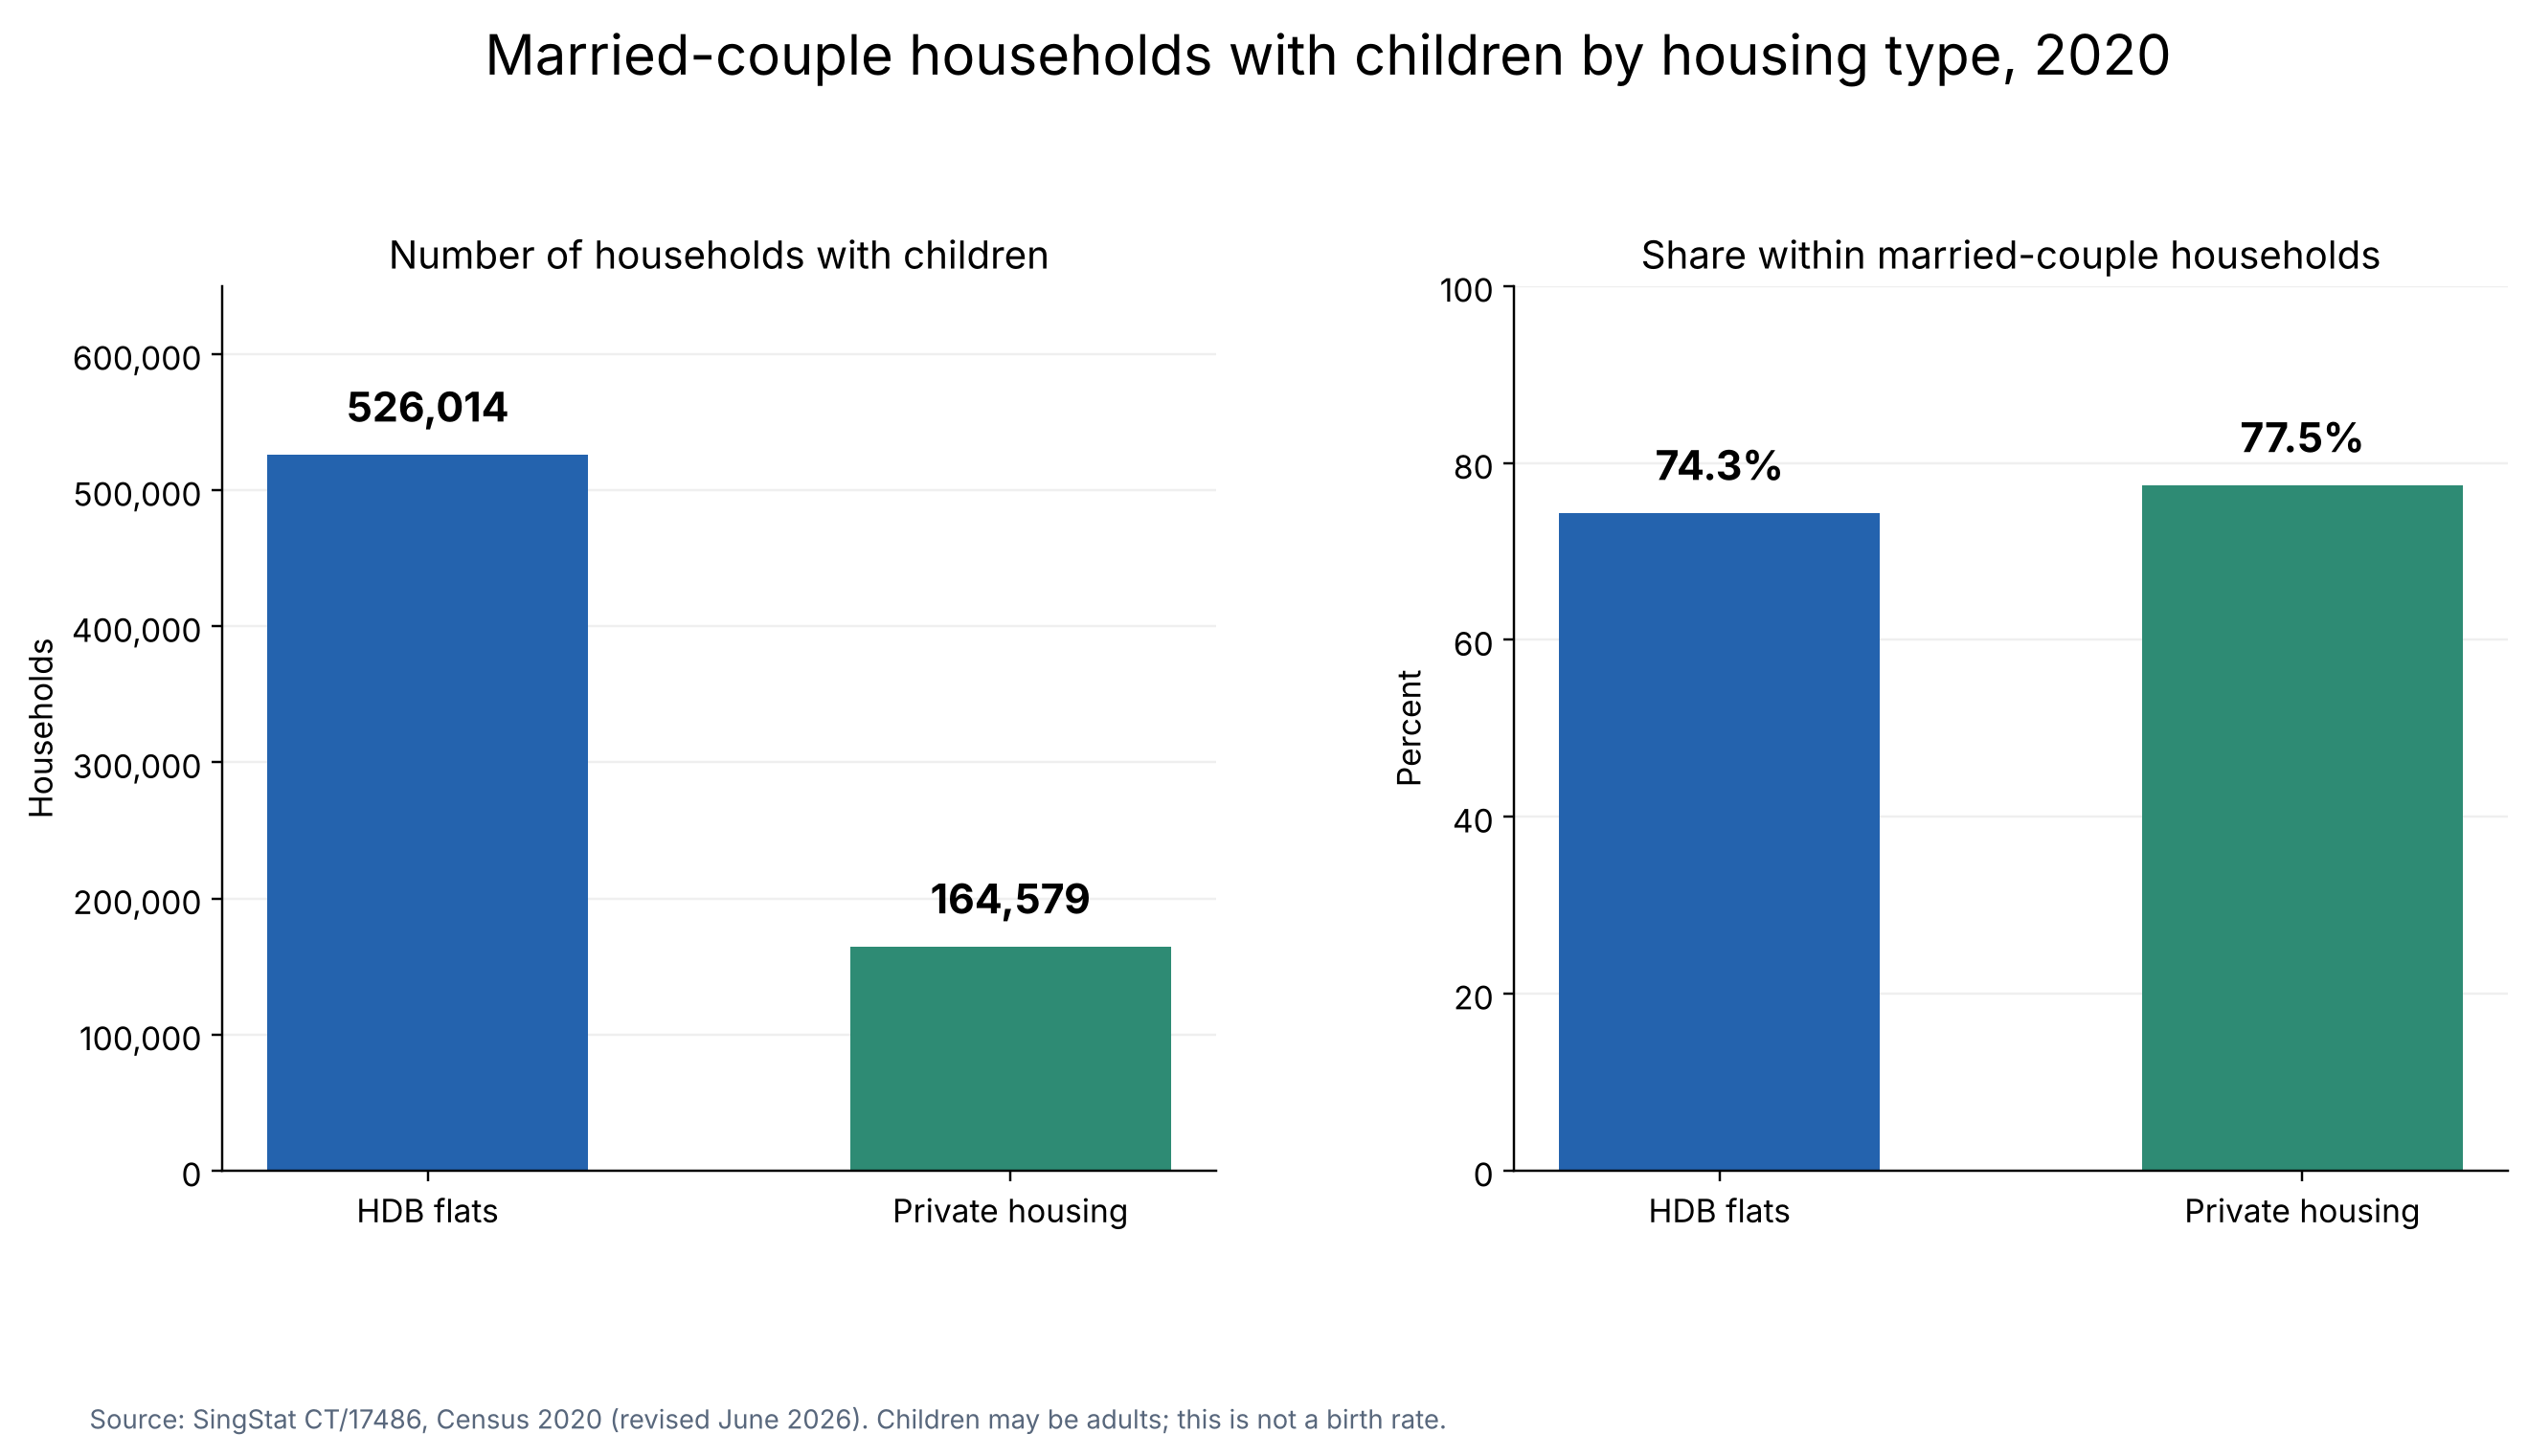

In [5]:
# 4. Census household counts and normalized percentages; not births or TFR.
households = pd.DataFrame({'Housing_Type':['HDB flats','Private housing'],
    'With_Children':[526014,120714+43865],
    'Without_Children':[181701,36881+10970]})
households['Share_With_Children_Percent'] = 100*households.With_Children / (
    households.With_Children+households.Without_Children)
households.to_csv(OUT/'Census_2020_Married_Couple_Households.csv', index=False)
fig, axes = plt.subplots(1,2,figsize=(14,7))
fig.subplots_adjust(bottom=.2, top=.8, wspace=.3)
fig.suptitle('Married-couple households with children by housing type, 2020',fontsize=19)
for ax, column, title, ylabel, limit in zip(axes,
    ['With_Children','Share_With_Children_Percent'],
    ['Number of households with children','Share within married-couple households'],
    ['Households','Percent'], [650000,100]):
    bars=ax.bar(households.Housing_Type, households[column],color=['#2463ae','#2e8b74'],width=.55)
    ax.set(title=title,ylabel=ylabel,ylim=(0,limit));ax.grid(axis='y',alpha=.2);ax.set_axisbelow(True)
    labels=[f'{v:,.0f}' if column=='With_Children' else f'{v:.1f}%' for v in households[column]]
    ax.bar_label(bars,labels=labels,padding=8,fontsize=14,weight='bold')
axes[0].yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
save(fig,'02_households_with_children.png',
     'Source: SingStat CT/17486, Census 2020 (revised June 2026). Children may be adults; this is not a birth rate.')
display(Image(filename=str(OUT / '02_households_with_children.png')))

## Figures 3 and 4: Age-Specific Fertility Rates, 2000–2025 and 2000 versus 2025

Age-specific fertility rates are births per 1,000 women in each age group. Rates fell across the groups below age 35. For women aged 25–29, the rate declined from 110.1 to 38.1; for those aged 30–34, it declined from 107.9 to 69.7. Rates increased from 43.3 to 46.0 among women aged 35–39 and from 7.6 to 9.5 among women aged 40–44. These patterns are consistent with childbearing shifting towards older ages. They do not show that housing prices caused the shift, or that later childbearing fully compensated for lower fertility at younger ages.

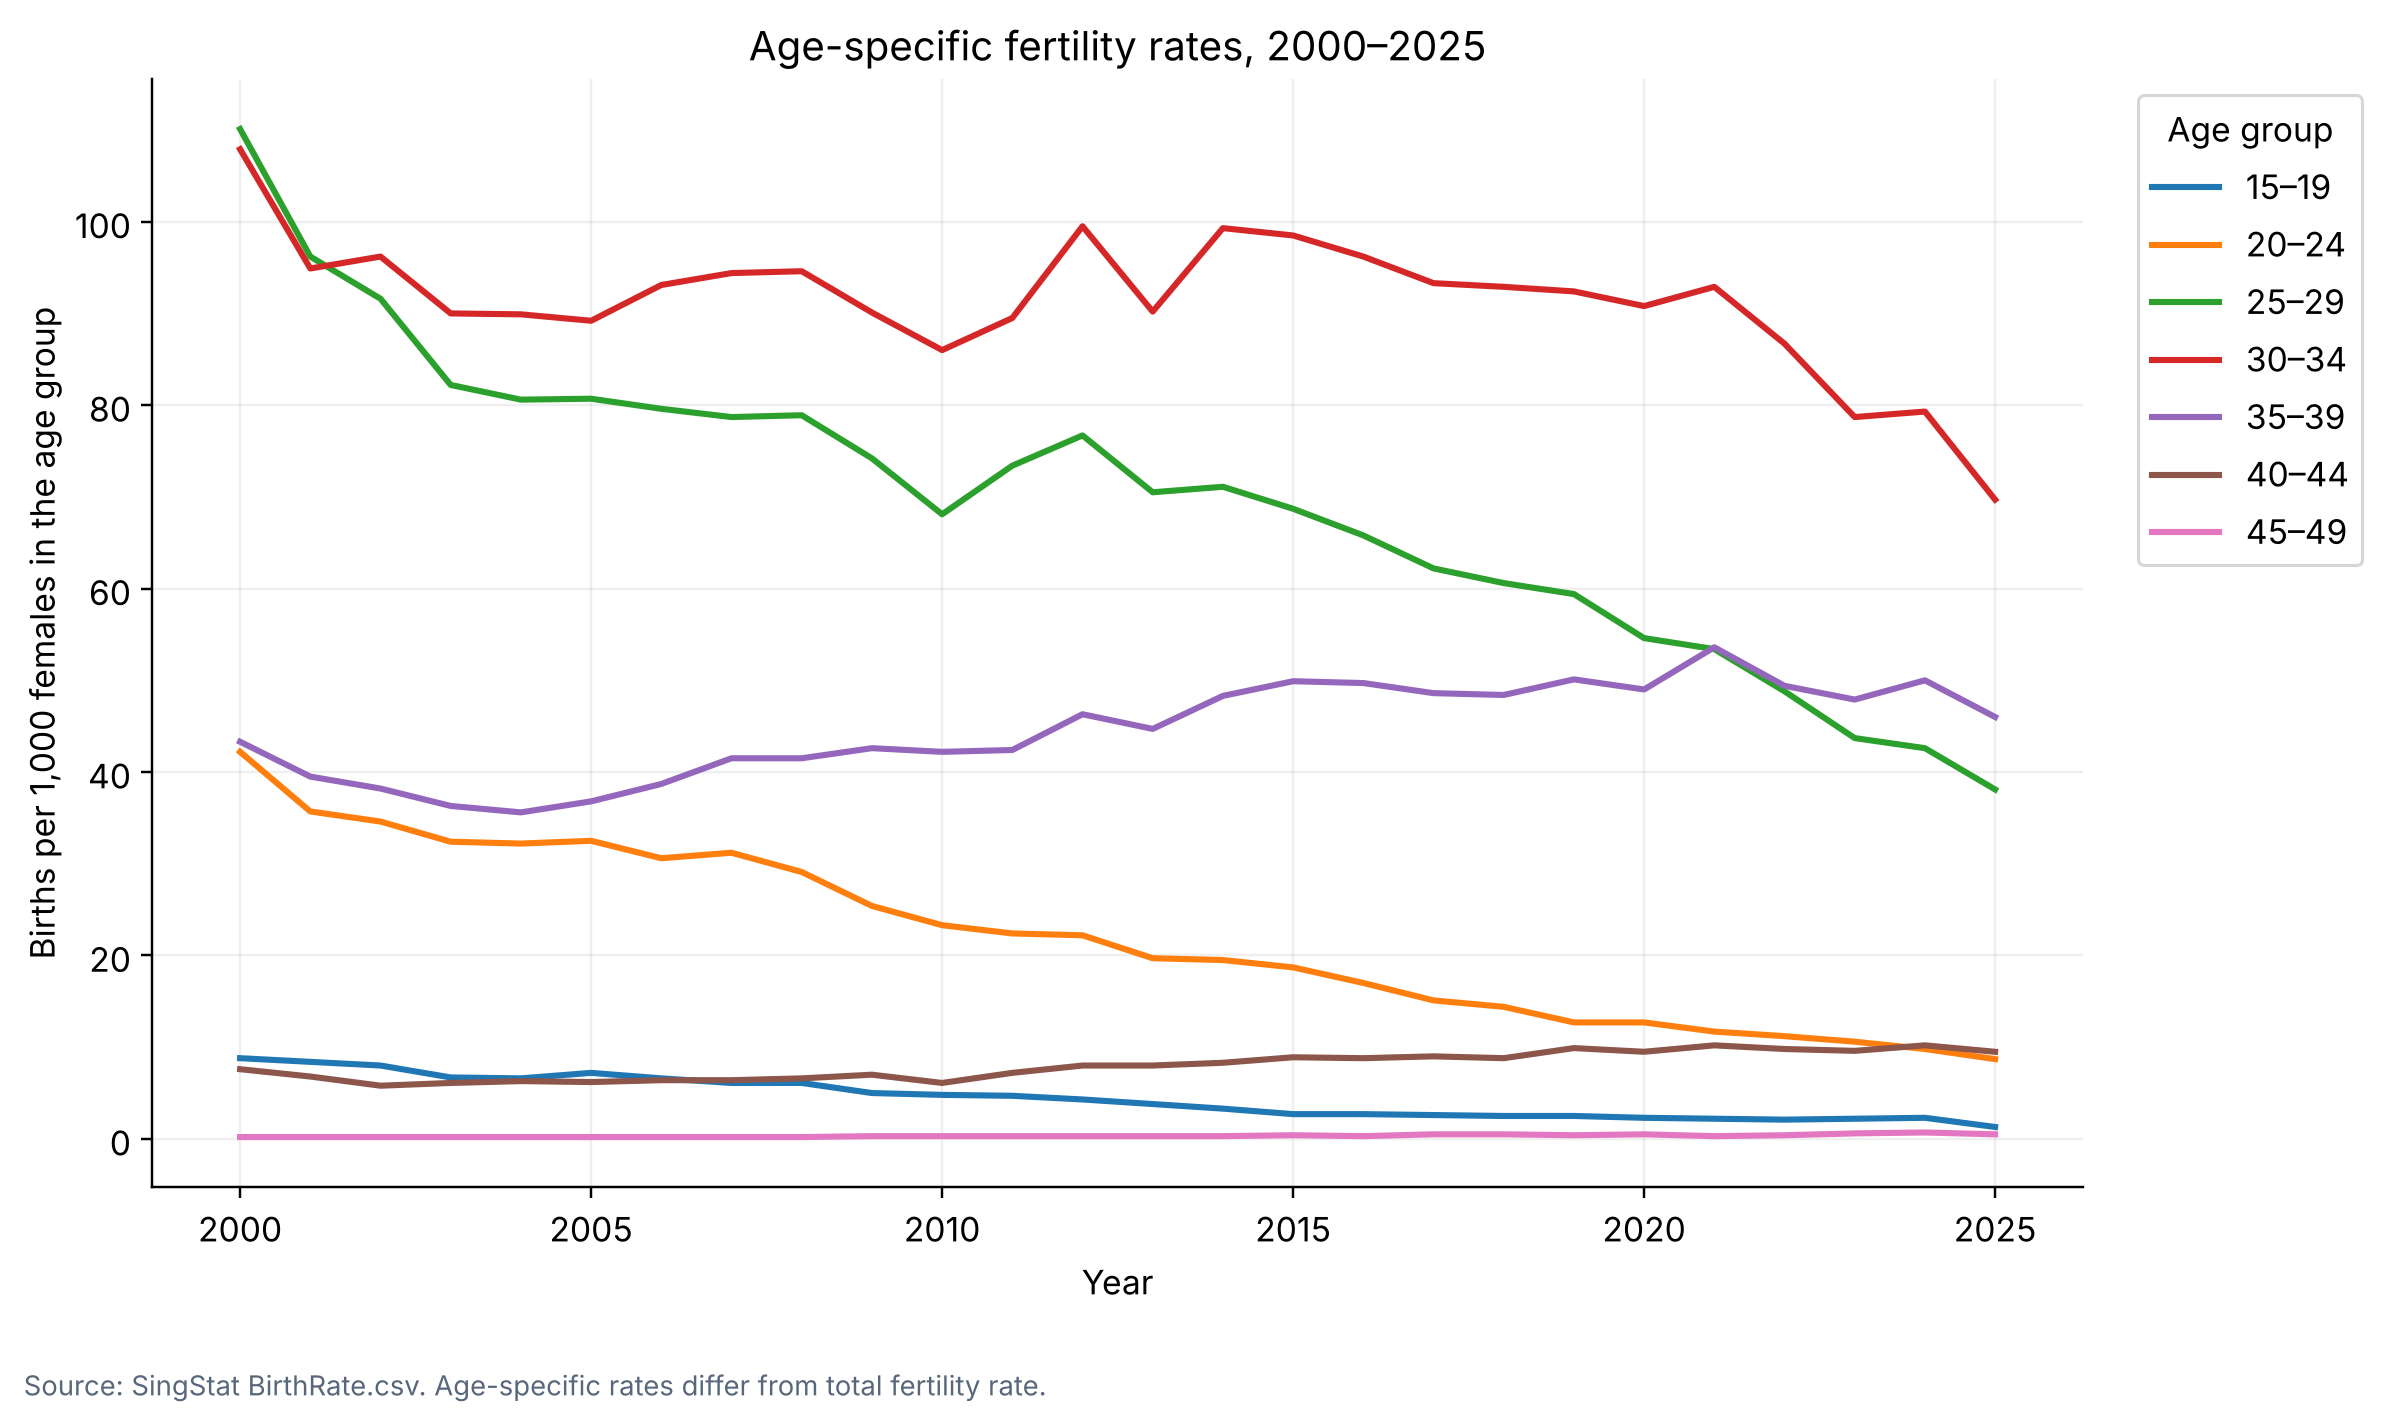

In [6]:
# 5. Age-specific fertility line and endpoint bar charts.
fig,ax=plt.subplots(figsize=(13,7));fig.subplots_adjust(bottom=.16,right=.8)
for age,label in zip(AGES,LABELS):ax.plot(df.Year,df[age],label=label,linewidth=2)
ax.set(title='Age-specific fertility rates, 2000–2025',xlabel='Year',ylabel='Births per 1,000 females in the age group')
ax.legend(title='Age group',bbox_to_anchor=(1.02,1),loc='upper left');ax.grid(alpha=.2)
save(fig,'03_age_fertility_lines.png','Source: SingStat BirthRate.csv. Age-specific rates differ from total fertility rate.')
display(Image(filename=str(OUT / '03_age_fertility_lines.png')))

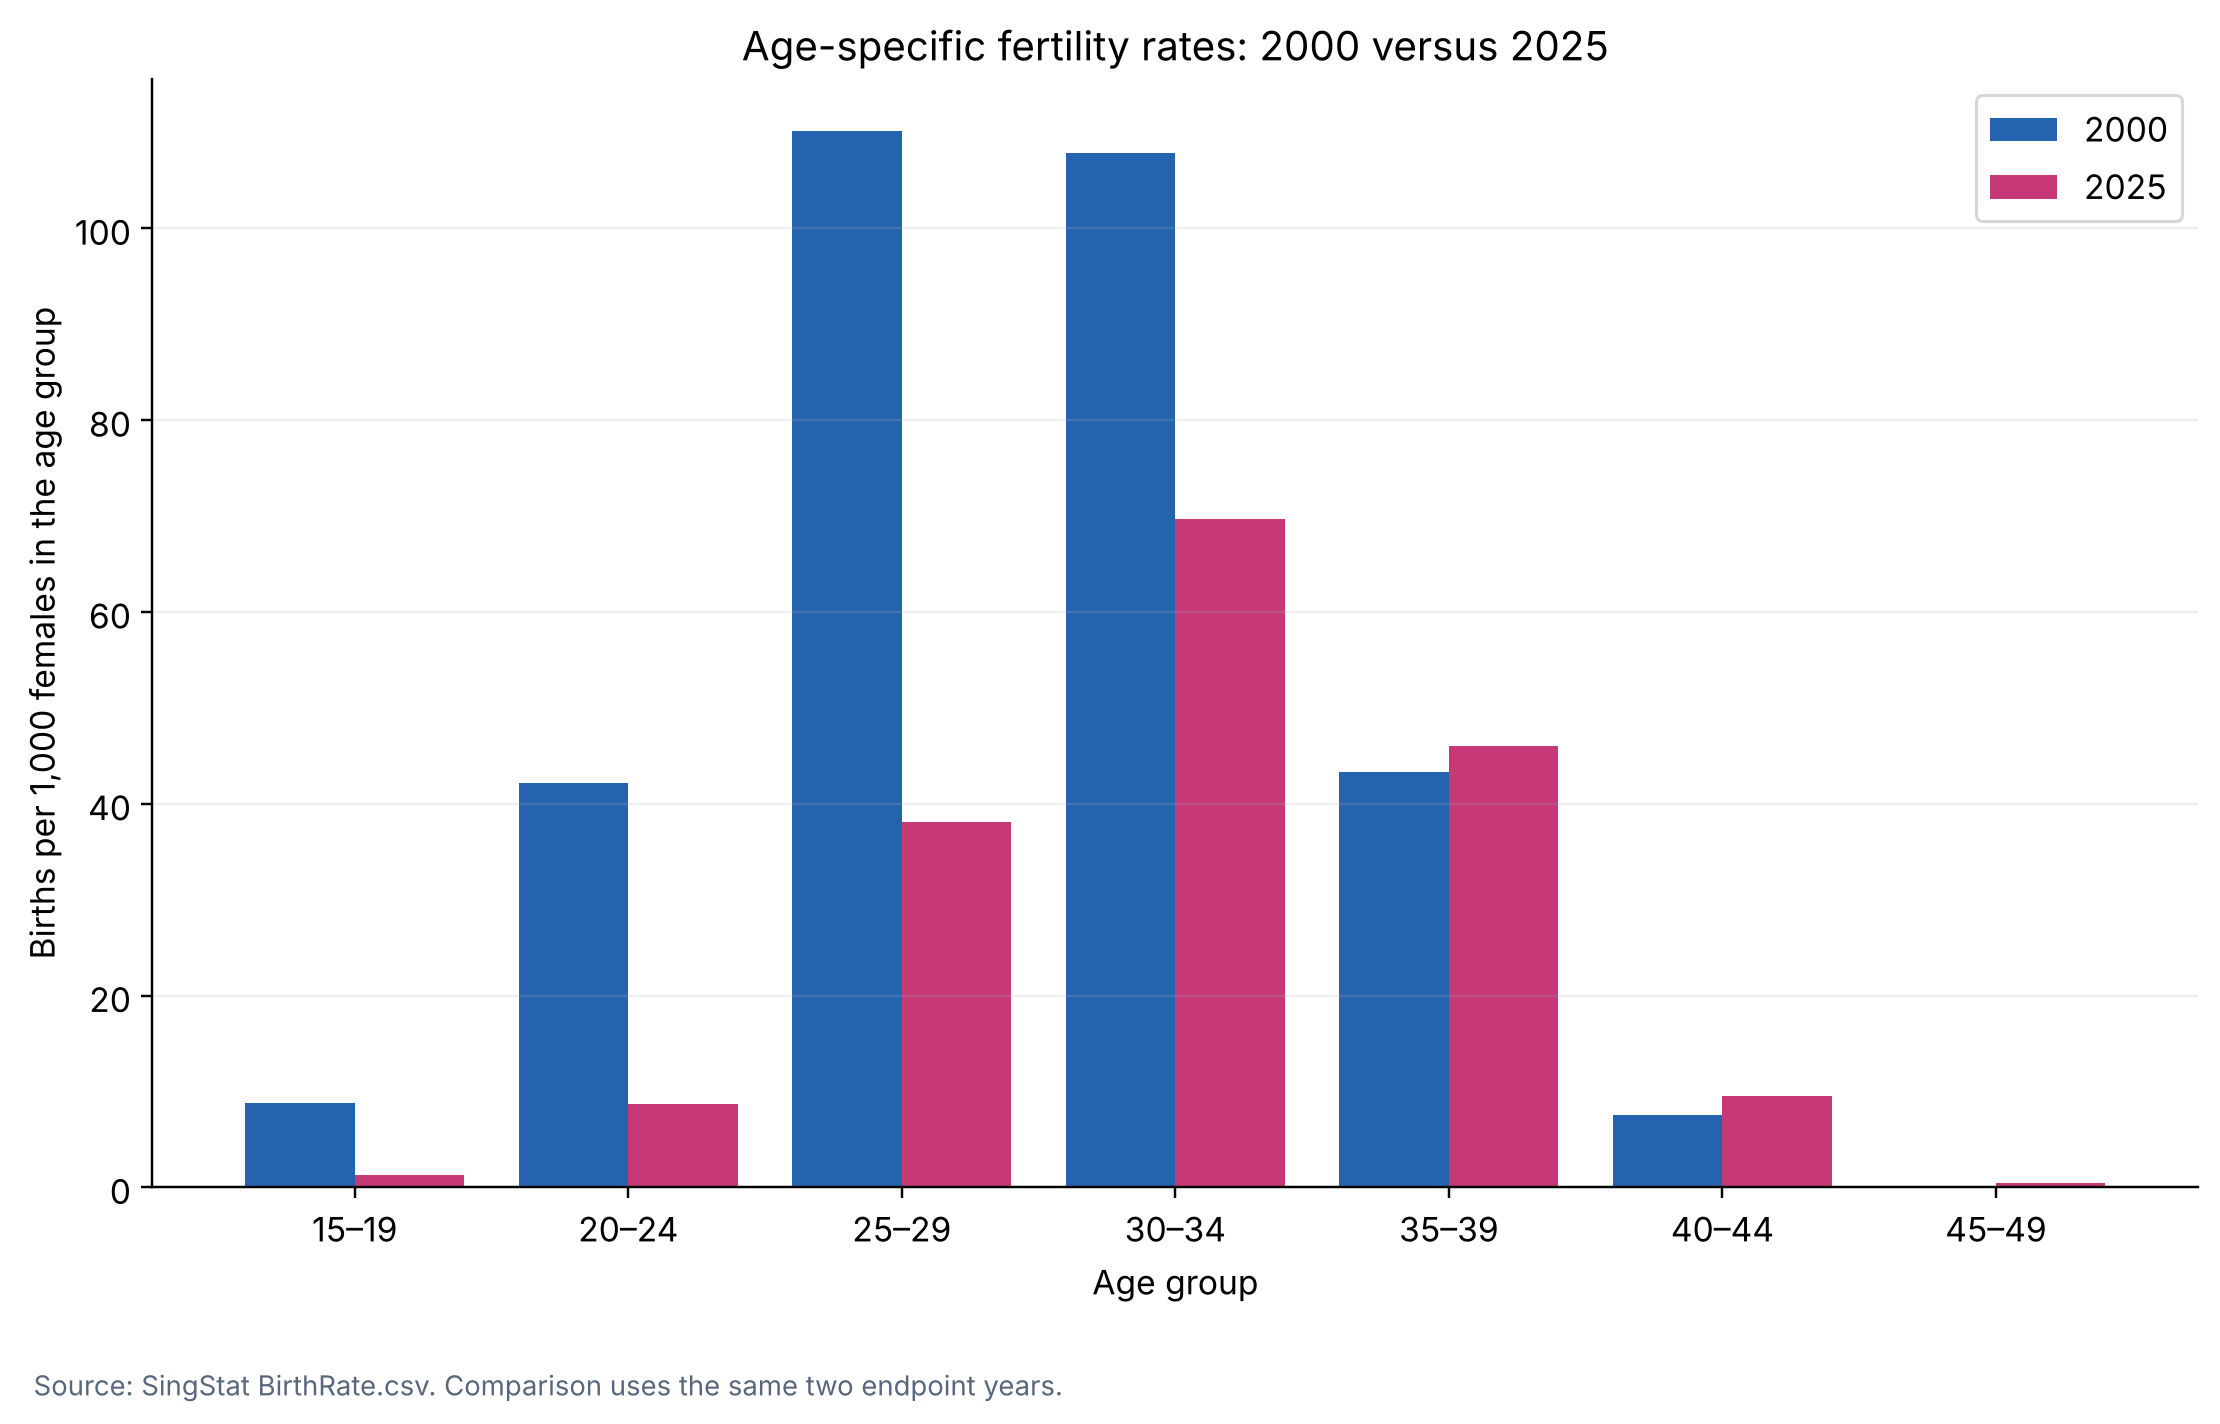

In [7]:
fig,ax=plt.subplots(figsize=(12,7));fig.subplots_adjust(bottom=.16)
x=np.arange(len(AGES))
ax.bar(x-.2,df.loc[0,AGES],width=.4,label='2000',color='#2463ae')
ax.bar(x+.2,df.loc[len(df)-1,AGES],width=.4,label='2025',color='#c63878')
ax.set(title='Age-specific fertility rates: 2000 versus 2025',ylabel='Births per 1,000 females in the age group',xlabel='Age group')
ax.set_xticks(x,LABELS);ax.legend();ax.grid(axis='y',alpha=.2)
save(fig,'04_age_fertility_bars.png','Source: SingStat BirthRate.csv. Comparison uses the same two endpoint years.')
display(Image(filename=str(OUT / '04_age_fertility_bars.png')))

## Figure 5: Correlation between HDB Resale Prices and Age-Specific Fertility Rates, 2000–2025

Pearson correlations are negative for women aged 15–19 (-0.900), 20–24 (-0.916), 25–29 (-0.879), and 30–34 (-0.572). They are positive for ages 35–39 (0.784), 40–44 (0.842), and 45–49 (0.825). These descriptive correlations reflect associations between annual levels and may be strongly influenced by shared time trends. A positive correlation for older ages does not mean that increasing house prices encourage childbirth; the underlying fertility levels are also much lower in the oldest groups.


Price growth, 2000–2025 (%)
HDB_Resale_Price_Index      159.17
Private_Landed_Index        145.47
Private_Non_Landed_Index    112.08
dtype: float64

Age-specific correlations with HDB prices:
 15 - 19 Years   -0.900
20 - 24 Years   -0.916
25 - 29 Years   -0.879
30 - 34 Years   -0.572
35 - 39 Years    0.784
40 - 44 Years    0.842
45 - 49 Years    0.825
dtype: float64


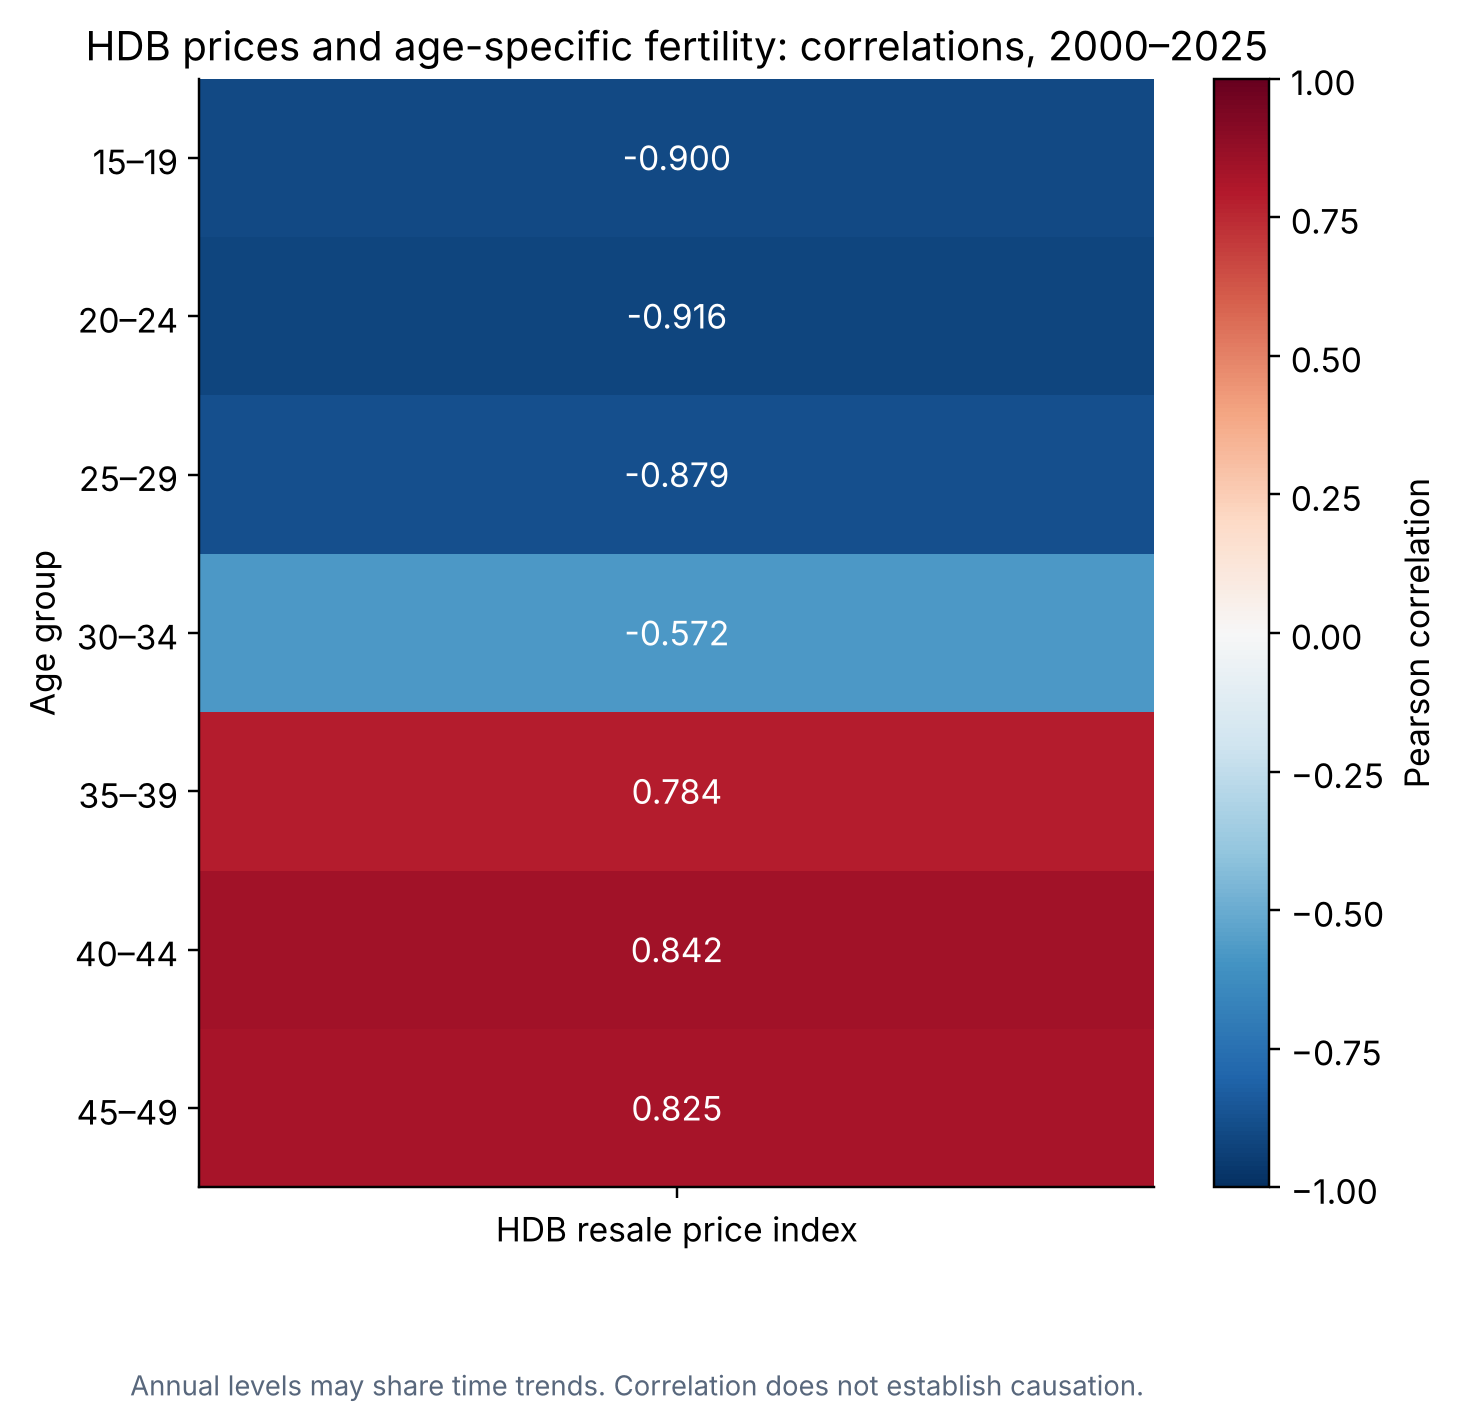

In [8]:
# 6. Pearson correlation of annual levels; descriptive, subject to time trends.
corr=df[AGES].corrwith(df.HDB_Resale_Price_Index)
corr.rename('Pearson_r').to_csv(OUT/'Age_HDB_Correlations.csv',index_label='Age_Group')
fig,ax=plt.subplots(figsize=(7,7));fig.subplots_adjust(bottom=.16)
img=ax.imshow(corr.to_numpy()[:,None],cmap='RdBu_r',vmin=-1,vmax=1,aspect='auto')
ax.set_xticks([0],['HDB resale price index']);ax.set_yticks(range(len(AGES)),LABELS)
ax.set(title='HDB prices and age-specific fertility: correlations, 2000–2025',ylabel='Age group')
for i,value in enumerate(corr):ax.text(0,i,f'{value:.3f}',ha='center',va='center',color='white' if abs(value)>.55 else 'black')
fig.colorbar(img,ax=ax,label='Pearson correlation')
save(fig,'05_age_hdb_heatmap.png','Annual levels may share time trends. Correlation does not establish causation.')
print('\nPrice growth, 2000–2025 (%)')
print(((df.loc[len(df)-1,price_cols]/df.loc[0,price_cols]-1)*100).round(2))
print('\nAge-specific correlations with HDB prices:\n',corr.round(3))
display(Image(filename=str(OUT / '05_age_hdb_heatmap.png')))

## Housing conclusion

Housing prices rose substantially while total fertility declined from 2000 to 2025. Age-specific patterns suggest a shift towards later childbearing, while the Census snapshot shows how households with children are distributed between HDB and private housing. Together, these results motivate further investigation of housing affordability and family formation. They do not demonstrate that housing prices cause lower fertility. Household income, housing expenditure, marriage timing and family circumstances would be needed for a more direct assessment.